<p class="hz-kicker">Session 3 · Linear regression and model evaluation</p>

# What drives the monthly bill?

The commercial team at Cordillera Mobile wants two things: to know what actually drives a customer's monthly bill, and to estimate the bill of a customer who has not paid one yet. Today you build your first model to answer both, and you learn to say honestly how wrong it is.
<ul class="hz-lesson-meta"><li>≈ 85 min</li><li>11 ideas</li><li>Runs in your browser</li><li>Advance 3</li></ul>

## <span class="hz-step-n">01</span> Previously at Cordillera Mobile

Last session you cleaned the customer base: duplicates gone, spellings unified, impossible ages and bills fixed. You ended with **4,985 customers and 15 columns**, saved as the clean file we load below.

You also saw the first patterns. The clearest one: the bill depends a lot on the plan. Let's load the clean data and look at that again, because today we go **from a pattern to a model**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

CLEAN = "https://raw.githubusercontent.com/hizocar/usm-course-intensivo/main/docs/datasets/cordillera_mobile_clean.csv"
df = pd.read_csv(CLEAN)
print(f"{df.shape[0]:,} customers, {df.shape[1]} columns")


def usd(amount):
    # format a number as dollars with two decimals, for readable printouts
    return f"${amount:,.2f}"
df.head()

4,985 customers, 15 columns


,customer_id,signup_date,age,region,plan,contract,tenure_months,data_gb,call_minutes,intl_roaming,support_tickets,autopay,payment_method,monthly_bill,churned
0,CM-12254,2022-07-04,34,Metropolitana,Basic,12 months,50,7.1,270,0,2,1,Unknown,25.46,0
1,CM-10173,2026-06-26,31,Centro,Plus,12 months,3,19.0,310,0,0,0,Debit card,37.05,1
2,CM-11339,2020-05-29,38,Centro,Prepaid,Month-to-month,76,3.6,165,0,0,1,Credit card,11.43,0
3,CM-13440,2019-11-02,31,Centro,Unlimited,12 months,82,17.8,248,0,2,0,Debit card,40.97,0
4,CM-10214,2022-07-01,34,Metropolitana,Basic,Month-to-month,50,4.3,240,0,0,0,Cash,19.18,1


In [2]:
avg_bill = df.groupby("plan")["monthly_bill"].mean().sort_values()
for plan, bill in avg_bill.items():
    print(f"{plan:<10} average bill {usd(bill):>7}")

Prepaid    average bill  $14.79
Basic      average bill  $24.32
Plus       average bill  $39.29
Unlimited  average bill  $46.95


A Prepaid customer pays about \$15 on average and an Unlimited customer about \$47. But the plan is not the whole story: two Plus customers can have very different bills. Data used, minutes, roaming and the contract all seem to play a part.

A table of averages answers one question at a time. Today the commercial team wants something more useful: **a recipe that takes everything we know about a customer and produces an estimate of their bill**, and tells us how much each ingredient adds.

## <span class="hz-step-n">02</span> From a question to a model

Every model starts by naming two things:

- **The target `y`**: what we want to predict. Here, `monthly_bill`.
- **The features `X`**: what we know about a customer *before* we see the bill. Plan, contract, data used, minutes, roaming, region, and so on.

A **model** is a recipe that turns features into a prediction. *Training* the model means letting the data choose the amounts in the recipe. For a linear regression, the recipe looks like this:

`bill ≈ starting amount + (amount per GB × GB used) + (amount for roaming × roaming) + …`

In [3]:
y = df["monthly_bill"]
X = df.drop(columns=["customer_id", "signup_date", "churned", "monthly_bill"])

print("Target y:", y.name, "→", len(y), "values")
print("Features X:", X.shape[1], "columns →", list(X.columns))

Target y: monthly_bill → 4985 values
Features X: 11 columns → ['age', 'region', 'plan', 'contract', 'tenure_months', 'data_gb', 'call_minutes', 'intl_roaming', 'support_tickets', 'autopay', 'payment_method']


We dropped four columns, each for a reason:

- **`monthly_bill`** is the answer. If it stays in `X`, the model "predicts" the bill by reading it.
- **`customer_id`** is a label, like a name. `CM-10001` says nothing about how much someone pays.
- **`signup_date`** is a date, and what it tells us is already in `tenure_months`.
- **`churned`** is recorded *three months after* the bill. For a new customer we will never have it. Using information that would not exist at the moment of the prediction is called **leakage**: the model looks great in class and fails in real life.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "The commercial team wants to estimate the bill of a customer who signs up tomorrow. Which column must not be a feature?", "options": ["<code>data_gb</code>, because it changes every month", "<code>churned</code>, because we only learn it months after the bill", "<code>plan</code>, because it is text"], "answer": 1, "why": "A feature must be known at the moment you make the prediction. Whether a customer cancels is only known three months later, so using it would be leakage. Text columns like <code>plan</code> are fine: we will turn them into numbers in step 04.", "code": false}</script>
</div>

## <span class="hz-step-n">03</span> Train and test

The commercial team will not use the model on the customers we already have: they already know those bills. They will use it on **new** customers. So the only honest question is: *how well does the model do on customers it has never seen?*

We answer it by setting customers aside **before** training. The model learns from the **training set** (70%). The **test set** (30%) goes into a sealed envelope that we open once, at the very end, to grade the model.

<div class="hz-widget" data-widget="train-test-split">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_3_Monthly_Bill/">open this class on the course website</a> to use it.</p>
</div>

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Training set: {len(X_train):,} customers ({len(X_train) / len(X):.0%})")
print(f"Test set:     {len(X_test):,} customers ({len(X_test) / len(X):.0%})")

Training set: 3,489 customers (70%)
Test set:     1,496 customers (30%)


`train_test_split` shuffles the rows and cuts them 70/30. `random_state=42` fixes the shuffle, so you, your teammates and I get exactly the same split every time we run the notebook.

A quick sanity check: the two sets should look alike. If the test set were full of Unlimited customers, it would be a different exam.

In [5]:
print(f"Average bill, training set: {usd(y_train.mean())}")
print(f"Average bill, test set:     {usd(y_test.mean())}")
print()
print(pd.DataFrame({
    "train": X_train["plan"].value_counts(normalize=True),
    "test": X_test["plan"].value_counts(normalize=True),
}).round(3))

Average bill, training set: $30.40
Average bill, test set:     $29.78

           train   test
plan                   
Basic      0.305  0.294
Plus       0.289  0.287
Prepaid    0.233  0.253
Unlimited  0.173  0.165


<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "A teammate trains the model on all 4,985 customers and reports its error on those same customers. Why is that number not trustworthy?", "options": ["Because 4,985 customers is too few", "Because the model has already seen those bills: it is an exam with the answers", "Because the error should always be computed on the training set"], "answer": 1, "why": "The model was fitted to those exact bills, so its error on them is flattering. A model that memorized them would score perfectly and still fail on tomorrow's customers. Only customers held out before training give an honest grade.", "code": false}</script>
</div>

## <span class="hz-step-n">04</span> Categories become numbers

A linear regression multiplies each feature by a number. It can multiply `18` GB by \$0.30, but it cannot multiply `"Plus"`. Four of our columns are text: `plan`, `contract`, `region` and `payment_method`. Let's see what happens if we try anyway.

In [6]:
try:
    LinearRegression().fit(X_train, y_train)
except Exception as e:
    print(type(e).__name__, "→", str(e)[:120])

ValueError → could not convert string to float: 'Sur'


The fix is **one-hot encoding**: each category gets its own column, with a 1 if the customer belongs to it and 0 otherwise. pandas does it with `pd.get_dummies`.

<div class="hz-widget" data-widget="one-hot">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_3_Monthly_Bill/">open this class on the course website</a> to use it.</p>
</div>

In [7]:
sample = X[["plan"]].head(6)
pd.concat([sample, pd.get_dummies(sample["plan"], prefix="plan", dtype=int)], axis=1)

,plan,plan_Basic,plan_Plus,plan_Prepaid,plan_Unlimited
0,Basic,1,0,0,0
1,Plus,0,1,0,0
2,Prepaid,0,0,1,0
3,Unlimited,0,0,0,1
4,Basic,1,0,0,0
5,Plus,0,1,0,0


Every row has exactly one 1, so one column is always redundant: if a customer is not Basic, Plus or Unlimited, they must be Prepaid. `drop_first=True` removes the first category's column, and that category becomes the **reference**: the coefficients of the other categories will read as "dollars more (or less) than the reference".

pandas drops the first category *in alphabetical order* unless we say otherwise. That would make Basic the reference plan and "12 months" the reference contract. It reads much better for a manager if the reference is the **simplest deal**: Prepaid, month-to-month. So we set the order first.

In [8]:
X = X.copy()
X["plan"] = pd.Categorical(X["plan"], categories=["Prepaid", "Basic", "Plus", "Unlimited"])
X["contract"] = pd.Categorical(X["contract"], categories=["Month-to-month", "12 months", "24 months"])

X_enc = pd.get_dummies(X, columns=["plan", "contract", "region", "payment_method"], drop_first=True, dtype=int)
print("Before:", X.shape[1], "columns   After:", X_enc.shape[1], "columns")
print(list(X_enc.columns))

Before: 11 columns   After: 19 columns
['age', 'tenure_months', 'data_gb', 'call_minutes', 'intl_roaming', 'support_tickets', 'autopay', 'plan_Basic', 'plan_Plus', 'plan_Unlimited', 'contract_12 months', 'contract_24 months', 'region_Metropolitana', 'region_Norte', 'region_Sur', 'payment_method_Cash', 'payment_method_Credit card', 'payment_method_Debit card', 'payment_method_Unknown']


11 columns became 19. The references, which no longer have a column, are **Prepaid**, **Month-to-month**, **Centro** (region) and **Bank transfer** (payment method).

Now we look up the *same customers* we split in step 03. The split is just a list of row labels, so `.loc` with the training and test indexes gives us their encoded rows. The test set stays sealed.

In [9]:
X_train = X_enc.loc[X_train.index]
X_test = X_enc.loc[X_test.index]
print("X_train:", X_train.shape, "  X_test:", X_test.shape)
X_train.head(3)

X_train: (3489, 19)   X_test: (1496, 19)


,age,tenure_months,data_gb,call_minutes,intl_roaming,support_tickets,autopay,plan_Basic,plan_Plus,plan_Unlimited,contract_12 months,contract_24 months,region_Metropolitana,region_Norte,region_Sur,payment_method_Cash,payment_method_Credit card,payment_method_Debit card,payment_method_Unknown
801,38,82,4.0,229,0,2,0,1,0,0,1,0,0,0,1,0,0,1,0
1288,36,70,7.5,159,0,2,0,1,0,0,1,0,1,0,0,0,0,1,0
2168,38,60,4.2,205,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0


## <span class="hz-step-n">05</span> Fitting a line

Let's start small, with one plan and one feature: **for Plus customers, how does the bill grow with the data they use?** A straight line through the cloud of points gives an answer: the slope is "dollars per extra GB".

But which line? Among all possible lines, linear regression picks the one with the **least squares**: it makes the sum of the squared vertical misses as small as possible. The explainer below uses a toy example (ad spend and sales) to show what that means. Drag the line and watch the total area of the squares.

<div class="hz-widget" data-widget="least-squares">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_3_Monthly_Bill/">open this class on the course website</a> to use it.</p>
</div>

In [10]:
plus = y_train.index[X_train["plan_Plus"] == 1]      # Plus customers in the training set
gb_plus = X_train.loc[plus, ["data_gb"]]
bill_plus = y_train.loc[plus]

simple = LinearRegression().fit(gb_plus, bill_plus)
print(f"{len(plus):,} Plus customers in the training set")
print(f"Intercept: {usd(simple.intercept_)}   Slope: {usd(simple.coef_[0])} per GB")

1,008 Plus customers in the training set
Intercept: $31.41   Slope: $0.53 per GB


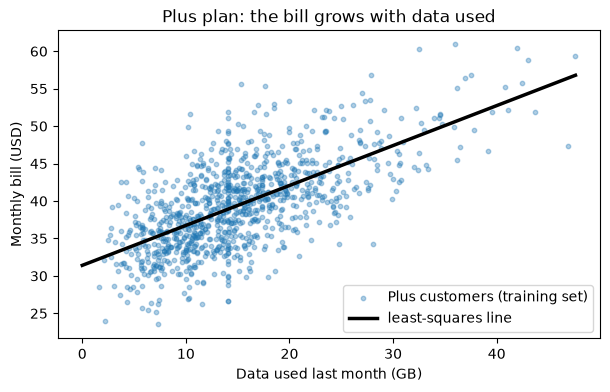

In [11]:
grid = pd.DataFrame({"data_gb": np.linspace(0, gb_plus["data_gb"].max(), 50)})

plt.figure(figsize=(7, 4))
plt.scatter(gb_plus["data_gb"], bill_plus, s=10, alpha=0.35, label="Plus customers (training set)")
plt.plot(grid["data_gb"], simple.predict(grid), color="black", linewidth=2.5, label="least-squares line")
plt.title("Plus plan: the bill grows with data used")
plt.xlabel("Data used last month (GB)")
plt.ylabel("Monthly bill (USD)")
plt.legend()
plt.show()

Read it like a manager: **a Plus customer pays about \$31 before any data, and each extra GB adds about \$0.53.** The cloud around the line is everything else: minutes, roaming, contract, and plain noise.

To use everything at once we do **multiple regression**: the same least-squares idea, but with one coefficient per feature. The code barely changes.

In [12]:
model = LinearRegression()
model.fit(X_train, y_train)
print(f"Trained on {len(X_train):,} customers and {X_train.shape[1]} features.")
print(f"Intercept: {model.intercept_:.3f} dollars")

Trained on 3,489 customers and 19 features.
Intercept: 10.019 dollars


## <span class="hz-step-n">06</span> Reading the coefficients like a manager

Each coefficient answers one question: **if this feature goes up by one, and everything else stays the same, how many dollars does the bill change?** For a 0/1 column, "goes up by one" means "belongs to this category instead of the reference".

In [13]:
coefs = pd.DataFrame({"feature": X_train.columns, "coefficient": model.coef_})
coefs = coefs.sort_values("coefficient", ascending=False).round(3).reset_index(drop=True)
coefs

,feature,coefficient
0,plan_Unlimited,26.701
1,plan_Plus,23.089
2,plan_Basic,10.160
3,intl_roaming,7.951
4,data_gb,0.275
5,payment_method_Unknown,0.244
6,payment_method_Credit card,0.172
7,region_Sur,0.065
8,call_minutes,0.012
9,tenure_months,0.004


Now translate the table into sentences the commercial team can use:

- **Plan, compared with Prepaid:** a Basic customer pays about **\$10.16** more, Plus **\$23.09** more, Unlimited **\$26.70** more, with everything else equal.
- **Roaming** adds about **\$7.95** to the bill.
- **Contract, compared with month-to-month:** a 12-month contract is about **\$1.86** cheaper, and a 24-month contract about **\$4.00** cheaper.
- **Data:** each extra GB adds about **\$0.28**. **Minutes:** about **\$0.012** each, so 100 extra minutes ≈ \$1.20.
- **Everything else** (age, tenure, support tickets, region, payment method, autopay): each moves the bill by about \$0.25 or less. They barely matter.

Wait: on Plus the slope was \$0.53 per GB, and now it's \$0.28. The full model has **one price per GB for everyone**, and Unlimited customers use a lot of data without paying for it. The model splits the difference. Keep that in mind; it comes back in step 08.

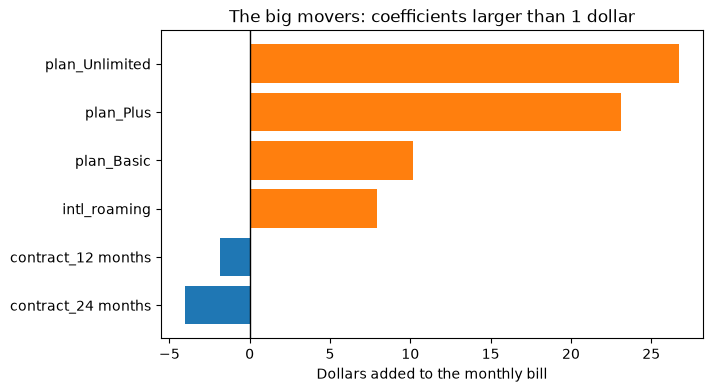

In [14]:
top = coefs[coefs["coefficient"].abs() > 1].sort_values("coefficient")
plt.figure(figsize=(7, 4))
plt.barh(top["feature"], top["coefficient"], color=["tab:blue" if c < 0 else "tab:orange" for c in top["coefficient"]])
plt.axvline(0, color="black", linewidth=1)
plt.title("The big movers: coefficients larger than 1 dollar")
plt.xlabel("Dollars added to the monthly bill")
plt.show()

**Careful:** a coefficient's size depends on its unit. Minutes has a tiny coefficient (\$0.012), but customers talk hundreds of minutes, so it adds about \$3 to a typical bill. Never rank features by their raw coefficient alone.

Now the second request: **estimate a new customer's bill**. She is 30, lives in the Metropolitana region, just signed a 12-month Plus contract, pays automatically with a credit card, and expects to use 18 GB and 250 minutes a month, without roaming.

In [15]:
new_customer = pd.DataFrame([dict.fromkeys(X_train.columns, 0)])   # one row of zeros with the same columns
new_customer.loc[0, ["age", "data_gb", "call_minutes", "autopay"]] = [30, 18, 250, 1]
new_customer.loc[0, ["plan_Plus", "contract_12 months", "region_Metropolitana", "payment_method_Credit card"]] = 1

estimate = model.predict(new_customer)[0]
print(f"Estimated monthly bill: {usd(estimate)}")

Estimated monthly bill: $39.06


Where does that number come from? From adding up the coefficients. The explainer starts from this exact customer: change her plan, contract, data or roaming and watch each term's bar move.

<div class="hz-widget" data-widget="coef-explorer">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_3_Monthly_Bill/">open this class on the course website</a> to use it.</p>
</div>

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "The coefficient of <code>contract_24 months</code> is about −4.00. What does it mean?", "options": ["Customers on 24-month contracts pay 4 dollars a month in total", "A 24-month customer pays about 4 dollars less than an otherwise identical month-to-month customer", "Each extra month of contract lowers the bill by 4 dollars"], "answer": 1, "why": "Month-to-month is the reference contract (its column was dropped), so the 24-month coefficient compares against it, holding plan, data, minutes and everything else fixed.", "code": false}</script>
</div>

## <span class="hz-step-n">07</span> How wrong are we? MAE, RMSE, R²

Time to open the envelope. For each test customer, the **residual** is the actual bill minus the predicted bill. Three numbers summarize the residuals:

- **MAE** (mean absolute error): the average miss, in dollars. The easiest to explain.
- **RMSE** (root mean squared error): also in dollars, but it squares the misses first, so a few big misses weigh a lot.
- **R²**: the share of the differences between customers' bills that the model explains. 1 is perfect; 0 is no better than predicting the average bill for everyone.

<div class="hz-widget" data-widget="error-metrics">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_3_Monthly_Bill/">open this class on the course website</a> to use it.</p>
</div>

In [16]:
def report(name, y_true, y_pred):
    return {
        "set": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)
metrics = pd.DataFrame([report("train", y_train, pred_train), report("test", y_test, pred_test)]).set_index("set")
metrics.round(3)

,MAE,RMSE,R2
set,,,
train,2.706,3.433,0.928
test,2.870,3.560,0.924


In [17]:
mae = mean_absolute_error(y_test, pred_test)
print(f"On customers it has never seen, the model misses by {usd(mae)} on average,")
print(f"on bills that average {usd(y_test.mean())}. It explains {r2_score(y_test, pred_test):.0%} of the differences between bills.")

On customers it has never seen, the model misses by $2.87 on average,
on bills that average $29.78. It explains 92% of the differences between bills.


Is \$2.87 good? A number means little without a comparison. The simplest possible "model" predicts the same bill for everyone: the average of the training set. That is our **baseline**.

In [18]:
baseline = np.full(len(y_test), y_train.mean())
print(f"Baseline (always predict {usd(y_train.mean())}): MAE {usd(mean_absolute_error(y_test, baseline))}")
print(f"Our linear regression:                MAE {usd(mae)}")

Baseline (always predict $30.40): MAE $11.27
Our linear regression:                MAE $2.87


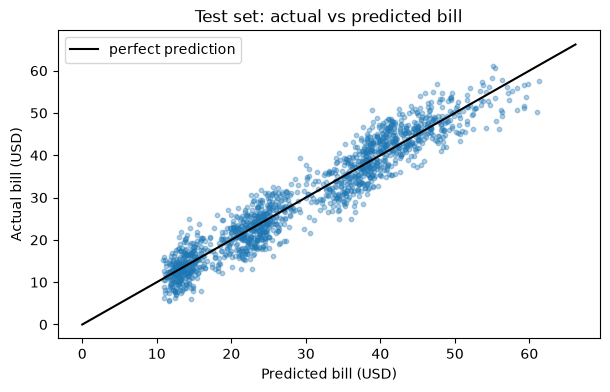

In [19]:
plt.figure(figsize=(7, 4))
plt.scatter(pred_test, y_test, s=10, alpha=0.35)
lims = [0, y_test.max() + 5]
plt.plot(lims, lims, color="black", linewidth=1.5, label="perfect prediction")
plt.title("Test set: actual vs predicted bill")
plt.xlabel("Predicted bill (USD)")
plt.ylabel("Actual bill (USD)")
plt.legend()
plt.show()

The points hug the diagonal: the model is about four times more accurate than the baseline. Train and test errors are close (\$2.71 vs \$2.87), which is the sign we want: the model learned patterns that also hold for new customers, instead of memorizing.

RMSE (\$3.56) is a bit above MAE, which tells us there are no huge misses: when a few customers are off by a lot, RMSE pulls far away from MAE.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Two models have the same MAE: 3 dollars. Model A has an RMSE of 3.4 dollars; model B, 7.9 dollars. What does that tell you?", "options": ["Model B is better, because a higher RMSE means more explained variation", "Model B has a few very large misses; model A's misses are more even", "Nothing: RMSE and MAE always move together"], "answer": 1, "why": "RMSE squares each miss before averaging, so a handful of big misses inflate it much more than MAE. If a surprise bill 20 dollars too high is what makes customers call to cancel, model A is the safer choice.", "code": false}</script>
</div>

## <span class="hz-step-n">08</span> Too simple, too complex

A model can fail in two opposite ways.

- **Too simple (underfitting):** it misses real patterns, so it is wrong on the training set *and* on the test set.
- **Too complex (overfitting):** it memorizes the training customers, noise included. Training error looks wonderful; test error is bad.

The explainer uses synthetic data (a sine wave with noise) and polynomials of growing degree. Watch the gap between the two errors.

<div class="hz-widget" data-widget="poly-fit">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_3_Monthly_Bill/">open this class on the course website</a> to use it.</p>
</div>

Now on our customers. We compare three recipes, always graded on the same sealed test set:

1. **Plan only**: the bill is the plan's average. Probably too simple.
2. **Full linear model**: the 19 features, as above.
3. **Every pair of features multiplied** (`PolynomialFeatures(degree=2)`): 209 columns, including things like "GB × Unlimited". We train it twice: on a small pilot of 150 customers, and on the whole training set.

In [20]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

def train_test_mae(estimator, cols=None, n=None):
    Xa = X_train if cols is None else X_train[cols]
    Xb = X_test if cols is None else X_test[cols]
    Xa, ya = (Xa, y_train) if n is None else (Xa.iloc[:n], y_train.iloc[:n])
    estimator.fit(Xa, ya)
    return mean_absolute_error(ya, estimator.predict(Xa)), mean_absolute_error(y_test, estimator.predict(Xb))

plan_cols = ["plan_Basic", "plan_Plus", "plan_Unlimited"]
rows = {
    "1. Plan only (3 columns)": train_test_mae(LinearRegression(), cols=plan_cols),
    "2. Full linear model (19 columns)": train_test_mae(LinearRegression()),
    "3a. All pairs, 150 customers (209 columns)": train_test_mae(make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()), n=150),
    "3b. All pairs, 3,489 customers (209 columns)": train_test_mae(make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression())),
}
compare = pd.DataFrame(rows, index=["train MAE", "test MAE"]).T
compare["gap"] = compare["test MAE"] - compare["train MAE"]
compare.round(2)

,train MAE,test MAE,gap
1. Plan only (3 columns),3.93,4.17,0.23
2. Full linear model (19 columns),2.71,2.87,0.16
"3a. All pairs, 150 customers (209 columns)",1.08,5.86,4.78
"3b. All pairs, 3,489 customers (209 columns)",2.53,2.71,0.17


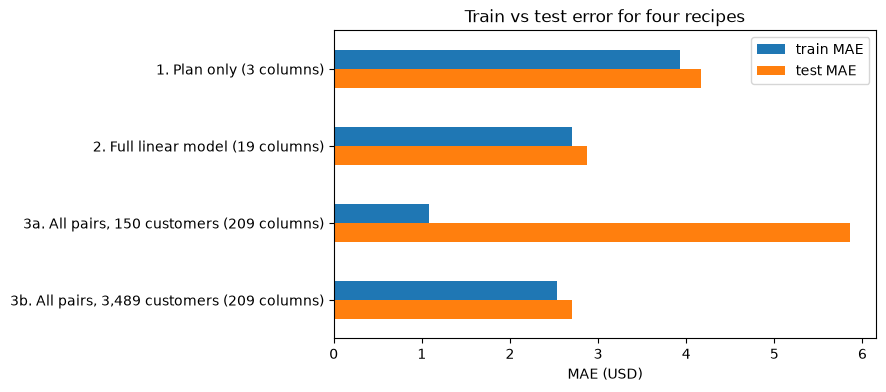

In [21]:
ax = compare[["train MAE", "test MAE"]].plot.barh(figsize=(7, 4), color=["tab:blue", "tab:orange"])
ax.invert_yaxis()
ax.set_title("Train vs test error for four recipes")
ax.set_xlabel("MAE (USD)")
plt.show()

Read the table from top to bottom:

- **Plan only** is wrong by about \$4 everywhere: too simple, it ignores data, roaming and contracts.
- **The full linear model** is better on both sets, with a small gap. A healthy model.
- **All pairs on 150 customers** is the classic overfit: about \$1 on the customers it trained on, almost \$6 on new ones. 209 columns and only 150 customers is enough to memorize.
- **The same complex recipe on 3,489 customers** does not overfit. It even beats the full linear model, because it can learn that Unlimited customers don't pay per GB (remember step 06).

**The lesson:** complexity is not bad in itself. Complexity without enough data is. And the only way to know is to look at the test error, never the training error alone.

## <span class="hz-step-n">09</span> Cross-validation: one test is one opinion

Our test MAE comes from one particular split. With another `random_state`, we would get a slightly different number. When we compare models, we don't want to pick a winner because of a lucky split, and we don't want to keep peeking at the sealed test set either.

**k-fold cross-validation** works only inside the training set: it cuts it into *k* folds, trains on *k − 1* and validates on the remaining one, *k* times. The explainer uses a housing dataset with R² as the score; we do the same with MAE on our customers.

<div class="hz-widget" data-widget="kfold">
<p>▶ Interactive explainer: <a href="https://hizocar.github.io/usm-course-intensivo/classes/Session_3_Monthly_Bill/">open this class on the course website</a> to use it.</p>
</div>

In [22]:
scores = cross_val_score(LinearRegression(), X_train, y_train, cv=5, scoring="neg_mean_absolute_error")
fold_mae = -scores    # scikit-learn reports "bigger is better", so the MAE comes out negative

for i, s in enumerate(fold_mae, start=1):
    print(f"Fold {i}: MAE {usd(s)}")
print(f"\nCross-validated MAE: {usd(fold_mae.mean())} ± {usd(fold_mae.std())}")

Fold 1: MAE $2.62
Fold 2: MAE $2.76
Fold 3: MAE $2.80
Fold 4: MAE $2.67
Fold 5: MAE $2.81

Cross-validated MAE: $2.73 ± $0.07


Five opinions instead of one, and they agree: about **\$2.73 ± \$0.07**. The spread is small, so the model's quality does not depend on which customers it happened to see. The test MAE (\$2.87) is in the same neighborhood, as it should be.

Why the minus sign? scikit-learn always maximizes its scores, so error metrics come out negative ("bigger is better"). We flip the sign to read them in dollars.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Why do we run <code>cross_val_score</code> on <code>X_train</code> and not on the whole table?", "options": ["Because cross-validation does not work with more than 3,489 rows", "To keep the test set sealed: it is only opened once, for the final grade", "Because the test set has no target column"], "answer": 1, "why": "Cross-validation is for comparing and choosing models. If we used the test set to choose, it would stop being an honest exam. It stays sealed until we report the final result.", "code": false}</script>
</div>

## <span class="hz-step-n">10</span> What we tell the commercial team

Three sentences, with numbers, and no jargon:

> **The plan sets most of the bill:** compared with Prepaid, Basic customers pay about \$10 more, Plus \$23 more and Unlimited \$27 more. On top of the plan, international roaming adds about \$8, each GB about \$0.28, and a 24-month contract takes about \$4 off compared with month-to-month.
>
> **For a new customer we can estimate the bill to within about \$3** (average miss on 1,496 customers the model never saw, on bills that average \$30), which is four times better than guessing the average bill.
>
> **The price per GB is not the same on every plan** (about \$0.53 on Plus, almost nothing on Unlimited); a model that treats plans separately would be more precise, and that is our next step.

Notice what's *not* in the message: no "R²", no "coefficient", no code. The numbers are in dollars, and each sentence answers something the commercial team asked.

## <span class="hz-step-n">11</span> Your project this week

Today's class is **[Advance 3 · Ready to model](https://hizocar.github.io/usm-course-intensivo/project/progress/#advance-3-ready-to-model)**, done on Cordillera. Here is the mirror:

| What we did with `monthly_bill` | Case A · TalentCo (`Salary`) | Case B · FinTrust Bank (`default`) |
|---|---|---|
| Chose `y` and `X`, dropped `customer_id` and leaky columns | Same: `y = Salary`, drop IDs | Same: `y = default`, drop IDs |
| `pd.get_dummies(..., drop_first=True)` on text columns | Same | Same |
| `train_test_split(test_size=0.3, random_state=42)` *before* any model | Same | Add `stratify=y`, so both sets keep the same share of defaults |
| `LinearRegression`, MAE / RMSE / R² on **train and test** | Same, with `Salary` | **Not yet.** Compute the accuracy of a model that always predicts "repays" |
| Cross-validation and coefficients in business terms | Due in Advance 4 | Logistic regression comes in session 4 |

**Case A** does exactly what we did today, with `Salary` as the target. Put the train and test metrics side by side and say whether you see overfitting.

**Case B** stops before the model: split with `stratify=y`, then compute the **baseline accuracy** of predicting "repays" for everyone, and explain in two lines why accuracy alone would be misleading.

**Case C** follows A or B, depending on whether your target is a number or a category.

Everyone adds a short paragraph: *what do you expect the model to find, based on your exploratory analysis?*

**Next session · Who is about to leave?** The retention team has a different question: not "how much", but "**who**". 16.5% of our customers cancel within three months. We'll see why a model that predicts "nobody leaves" is right 83.5% of the time and completely useless, and how to build one that tells the retention team whom to call.